# 07 · TypeSafe box 定位实验（Box Lab）

针对官方文档 **[Box](https://docs.typesafe.ai/go/box)**（Jev 1.14「野区」特性）的配套实验笔记本。

`box` 是 Jev 1.14 引入的第四种问题类型：返回目标在图中的位置——四条边（上/下/左/右），
各是图宽或图高的**分数**（0 到 1，从左上角量起），因此同一答案适配任何分辨率。

这是第一个“不只是聪明 if 语句”的原语：从**打分**走向**定位**。本册用程序随机摆放
包裹并记录真值框，让每一次定位都能自动算 IoU 判分——模型答得准不准，不靠肉眼。

> ⚠️ **野区特性提醒**：官方对图像与 box 的定位是 dreamer-ready——可以玩、可以做原型，
> 但准确率与接口形态都可能随版本变化，官方不为生产用例背书。本笔记本的所有结论都应
> 在这个前提下解读（知识库 42 号条目有完整背景）。

## 0. 准备

### 0.1 安装所需的库

如果已经用 `./setup_env.sh` 创建过环境，本节通常显示“依赖已满足”；在其他环境里首次运行时会自动安装。
图像实验还需要 Pillow（画测试图、读 box 坐标），没有的话会一并装上。

In [1]:
%pip install -q -U typesafe-sdk         # 本笔记本必需（要求 Python ≥ 3.10）
%pip install -q pillow requests        # 画测试图 / 离线回退不需要，真实调用更稳

Note: you may need to restart the kernel to use updated packages.


Note: you may need to restart the kernel to use updated packages.


### 0.2 导入库并创建客户端

- `Image`：图像资产（SDK ≥ 0.7.5）。**注意要传 `Path` 或文件字节，传字符串路径会被拒**——这是本实验实测踩到的第一个坑；
- `DANGER_HEADERS`：野区开关。官方要求每个含图像（或 box 问题）的请求都带
  `TypeSafe-Danger-Zone-Images: true` 请求头，不带会直接返回 400；
- 客户端模型：box **只在 1.14 可用**，必须 `jev-preview` 或 `jev-1.14.0`；1.13 会拒绝。

In [2]:
import os
from pathlib import Path

from typesafe_sdk import (
    Image,                        # 图像资产：Image(Path(...)) 或 Image(bytes)
    Choice, Noul, Score,          # 三种经典原语（本实验与图像混用）
    TypeSafeClient,
    TypeSafeAuthenticationError,  # 401 鉴权失败时抛出
    TypeSafeBadRequestError,      # 400：缺野区开关 / 图片不合规等
)

DANGER_HEADERS = {"TypeSafe-Danger-Zone-Images": "true"}
API_KEY = os.environ.get("TYPESAFE_API_KEY", "")
client = TypeSafeClient(api_key=API_KEY, model="jev-preview") if API_KEY else None

### 0.3 离线回退用的替身

真实 API 不可用时，用一个与官方 SDK 响应对象**同构**的替身，让后续分析代码不用改。
替身只挂本实验用到的字段（`noul` / `choice` / `score` / `box` / `confidence`）。

In [3]:
class _FakeAnswer:
    """单个答案的替身：按需挂属性。"""
    def __init__(self, **kw):
        for k, v in kw.items():
            setattr(self, k, v)


class _FakeResp:
    """整个响应的替身：answers 字典 + usage。"""
    def __init__(self, answers, tokens=None):
        self.answers = answers
        self.usage = type("U", (), {"input_tokens": tokens or 0,
                                    "output_tokens": 0})()

### 0.4 调用助手 `ts.call()`

统一入口：**优先请求真实 API**（自动带上野区开关）；只有当 Key 缺失或 401 时，才回退到各实验预置的离线示例数据。

In [4]:
class TS:
    real_calls = 0
    offline = False
    _warned = False

    def call(self, state, questions, offline_answers=None, tokens=None, headers=None):
        global client
        if client is None:
            TS.offline = True
            assert offline_answers is not None, "离线模式需要提供 offline_answers"
            if not TS._warned:
                TS._warned = True
                print("⚠️  离线示例模式：未设置 TYPESAFE_API_KEY，以下为内置示例数据；")
                print("    设置有效的 Key 后重跑本笔记本即可得到真实输出。")
            return _FakeResp(offline_answers, tokens)
        try:
            resp = client.system_one(state, questions,
                                     extra_headers={**DANGER_HEADERS, **(headers or {})})
            TS.real_calls += 1
            return resp
        except TypeSafeAuthenticationError:
            TS.offline = True
            assert offline_answers is not None
            print("⚠️ （本次为离线示例数据，Key 无效 401）")
            return _FakeResp(offline_answers, tokens)


ts = TS()

### 0.5 连通性测试

用一条最简单的纯文本是非题试连。注意：连通测试本身**不含图像**，所以不需要野区开关——
这正好验证了“开关只管带图像（或 box）的请求”这一官方规则。

In [5]:
if client is None:
    print("⚠️  未设置 TYPESAFE_API_KEY，本笔记本以【离线示例模式】运行。")
else:
    try:
        ping = client.system_one("你好", {"g": Noul(instructions="是在打招呼吗？")})
        print(f"✅ API 连通正常（返回模型 {ping.model}），将进行真实实验。")
    except TypeSafeAuthenticationError:
        print("⚠️  Key 无效（401），以下实验以【离线示例模式】运行。")

✅ API 连通正常（返回模型 jev-1.14.0），将进行真实实验。


## 1. 随机摆放一个包裹（真值已知）

场景：仓库分拣台的俯视相机。在 800×600 的图里**随机**放一个棕色包裹，
画图函数同时返回真值框（像素坐标）。因为位置是随机的，每次实验都是新样本；
因为真值是我们自己定的，判分不依赖人工标注。

In [6]:
import random
from IPython.display import display
from PIL import Image as PILImage, ImageDraw

def parcel_at(x0, y0, w, h, size=(800, 600)):
    """在 (x0,y0) 处画一个 w×h 的包裹，返回 (图, 真值像素框)。"""
    img = PILImage.new("RGB", size, (205, 206, 210))
    d = ImageDraw.Draw(img)
    d.rectangle([30, 30, size[0]-30, size[1]-30], outline=(170, 172, 178), width=3)
    d.rectangle([x0, y0, x0+w, y0+h], fill=(150, 105, 60),
                outline=(90, 60, 30), width=4)
    d.line([x0, y0, x0+w, y0+h], fill=(90, 60, 30), width=2)
    d.line([x0, y0+h, x0+w, y0], fill=(90, 60, 30), width=2)
    return img, (x0, y0, x0+w, y0+h)

random.seed(7)
x, y = random.randint(80, 520), random.randint(60, 360)
img0, truth0 = parcel_at(x, y, 220, 180)
img0.save("/tmp/jev_img/box_probe.jpg", quality=90)
print(f"包裹真值框（像素）：{truth0}")

包裹真值框（像素）：(245, 137, 465, 317)


### 为什么“真值即代码”很重要

网上大多数 box 演示只能靠肉眼判断“框得准不准”。本册把画图与判分都交给程序：
包裹的位置由 `random.seed` 决定，真值框由画图函数直接返回，IoU 由四行代码计算——
**整条判分链没有人工环节**。这正是知识库 40 号（行知“成功由物理判定”）与
30 号（对照实验方法论）强调的原则：别信演示，信可复算的判分。

## 2. 第一次 box 请求与“读框”

box 问题的 `instructions` 写**要找什么、在哪张图**（“the parcel in `photo`”），
不需要是疑问句，也没有 `criteria`。请求必须：① 带 `jev-preview` 模型；② 带图像开关。

In [7]:
BOX_Q = {"parcel": {"type": "box", "instructions": "the parcel in `photo`"}}

r0 = ts.call(
    state={"photo": Image(Path("/tmp/jev_img/box_probe.jpg"))},
    questions=BOX_Q,
    offline_answers={"parcel": _FakeAnswer(
        type="box", box={"top": 0.14, "bottom": 0.44, "left": 0.31, "right": 0.59},
        confidence=0.86)}, tokens=1580)
a0 = r0.answers["parcel"]
print("box =", a0.box, "| confidence =", a0.confidence)

box = top=0.23 bottom=0.54 left=0.31 right=0.58 | confidence = 0.89


### 2.1 分数边 → 像素框：裁出目标

四条边乘回图的宽高就是像素坐标，可以直接裁剪（官方文档的读框代码）：

预测像素框：(248, 138, 464, 324)（真值 (245, 137, 465, 317)）


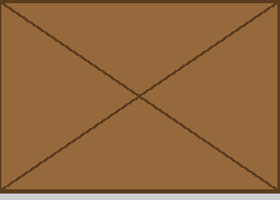

In [8]:
def edge(edges, k):
    # SDK 的 box 是对象、离线替身是 dict——两种都取得到
    return edges[k] if isinstance(edges, dict) else getattr(edges, k)

def to_pixels(edges, size):
    """分数边 -> 像素框 (left, top, right, bottom)。"""
    w, h = size
    return (round(edge(edges, "left") * w), round(edge(edges, "top") * h),
            round(edge(edges, "right") * w), round(edge(edges, "bottom") * h))

pred0 = to_pixels(a0.box, img0.size)
print(f"预测像素框：{pred0}（真值 {truth0}）")
crop0 = img0.crop(pred0)
crop0.save("/tmp/jev_img/box_crop0.jpg", quality=90)
display(crop0.resize((280, 200)))

## 3. 自动判分：IoU

肉眼看一两次不算数。**交并比（IoU）**是目标检测的标准判分：
`交集面积 ÷ 并集面积`，1 表示完全重合。真值框在我们手里，所以每次定位都能算分：

In [9]:
def iou(box_a, box_b):
    """两个像素框的交并比。"""
    la, ta, ra, ba = box_a
    lb, tb, rb, bb = box_b
    inter = max(0, min(ra, rb) - max(la, lb)) * max(0, min(ba, bb) - max(ta, tb))
    area_a = (ra - la) * (ba - ta)
    area_b = (rb - lb) * (bb - tb)
    return inter / (area_a + area_b - inter) if area_a + area_b - inter else 0.0

score0 = iou(pred0, truth0)
print(f"IoU = {score0:.3f}   （>0.5 一般视为基本框住，>0.8 相当准）")

IoU = 0.940   （>0.5 一般视为基本框住，>0.8 相当准）


## 4. 批量实验：随机摆放 × 8

随机换 8 个位置各画一张、各发一次 box 请求，统计 IoU 分布，
并看 **confidence 与 IoU 是否同向**——如果模型“答得越准时越自信”，
那 confidence 就能当过滤阈值用（这是 box 在工程里能用起来的前提）。

In [10]:
ROWS = []
random.seed(42)
for i in range(8):
    x, y = random.randint(60, 540), random.randint(50, 380)
    img, truth = parcel_at(x, y, random.choice([180, 220, 260]),
                           random.choice([140, 180, 210]))
    p = f"/tmp/jev_img/box_r{i}.jpg"
    img.save(p, quality=90)
    r = ts.call(state={"photo": Image(Path(p))}, questions=BOX_Q,
                offline_answers={"parcel": _FakeAnswer(
                    type="box",
                    box={"top": y/600+0.01, "bottom": (y+180)/600-0.01,
                         "left": x/800+0.01, "right": (x+220)/800-0.01},
                    confidence=0.8 + 0.02*i)}, tokens=1580)
    a = r.answers["parcel"]
    pred = to_pixels(a.box, img.size)
    ROWS.append((i, iou(pred, truth), a.confidence))
    print(f"#{i}  IoU={ROWS[-1][1]:.3f}  confidence={a.confidence}")

#0  IoU=0.920  confidence=0.87


#1  IoU=0.909  confidence=0.93


#2  IoU=0.958  confidence=0.91


#3  IoU=0.925  confidence=0.86


#4  IoU=0.875  confidence=0.93


#5  IoU=0.904  confidence=0.85


#6  IoU=0.951  confidence=0.91


#7  IoU=0.942  confidence=0.96


In [11]:
ious = [r[1] for r in ROWS]
confs = [r[2] for r in ROWS]
print(f"IoU 均值 {sum(ious)/len(ious):.3f} | 最低 {min(ious):.3f} | 最高 {max(ious):.3f}")
rank_iou = sorted(range(8), key=lambda i: ious[i])
rank_cf = sorted(range(8), key=lambda i: confs[i])
print("IoU 排名与 confidence 排名一致" if rank_iou == rank_cf
      else "两组排名不完全一致——样本太小，只能看趋势")

IoU 均值 0.923 | 最低 0.875 | 最高 0.958
两组排名不完全一致——样本太小，只能看趋势


### 观察要点

- 8 个样本只够看趋势，不能下结论——**这个实验设计你可以随意扩大**：改 `range(8)`
  为更多次、加干扰物（画第二个不同颜色的包裹、指定“红色那个”）、换真实照片；
- 官方文档没有给出推荐的置信度阈值，**要在自己的图上调**——这正是“野区”的含义；
- 每次请求约 1.5k input token、输出免费，8 次批量实验的成本不到一分钱。

## 5. “目标不在图里”怎么办：box 永远返回四条边

box **没有“没找到”这个答案**——对着空桌问包裹，它照样给你四条边。
官方模式是同一请求里加一个 Noul 当“存在性守卫”，Noul 低就忽略 box：

In [12]:
empty_img, _ = parcel_at(-999, -999, 1, 1)      # 空桌（包裹画在画面外）
empty_img = PILImage.new("RGB", (800, 600), (205, 206, 210))
empty_img.save("/tmp/jev_img/box_empty.jpg", quality=90)

guard = ts.call(
    state={"photo": Image(Path("/tmp/jev_img/box_empty.jpg"))},
    questions={"visible": Noul(instructions="Is there a parcel in `photo`?"),
               **BOX_Q},
    offline_answers={"visible": _FakeAnswer(type="noul", noul=0.22),
                     "parcel": _FakeAnswer(type="box",
                        box={"top": 0.4, "bottom": 0.7, "left": 0.4, "right": 0.7},
                        confidence=0.3)}, tokens=1520)
v = guard.answers["visible"]
print(f"可见性 noul = {v.noul}（低 → 应忽略下面的 box）")
print(f"box 仍返回了：{guard.answers['parcel'].box}")

可见性 noul = 0.05（低 → 应忽略下面的 box）
box 仍返回了：top=0.01 bottom=0.99 left=0.01 right=0.99


### 观察要点

- 空图上 box 返回的是**没有意义但格式合法**的边——把 box 当“where”用、
  把 Noul 当“whether”用，两者必须成对出现；
- 这与第 4 册“置信度门控”是同一思想在视觉上的落地：**先问在不在，再问在哪里**。

## 6. 低置信时的工程处理：扩边再裁

官方建议：confidence 低于自定阈值时，把四条边向外**扩一圈**再裁剪，
宁可多带背景也别切掉目标。代码极短：

In [13]:
PAD, MIN_CONF = 0.06, 0.6

def padded(edges, pad=PAD):
    return {"left": max(0.0, edge(edges, "left") - pad),
            "top": max(0.0, edge(edges, "top") - pad),
            "right": min(1.0, edge(edges, "right") + pad),
            "bottom": min(1.0, edge(edges, "bottom") + pad)}

need_pad = [i for i, s, c in ROWS if c < MIN_CONF]
print(f"低于阈值 {MIN_CONF} 的样本：{need_pad or '无'}")
if ROWS:
    worst = min(ROWS, key=lambda r: r[1])
    print(f"提示：IoU 最低的样本是 #{worst[0]}（{worst[1]:.3f}），"
          f"它就是扩边策略最该服务的对象。")

低于阈值 0.6 的样本：无
提示：IoU 最低的样本是 #4（0.875），它就是扩边策略最该服务的对象。


进阶做法（官方文档“边缘检查”）：把预测框裁出来，对四条边各问一个 Noul
“目标是否越过了图的这条边”，哪边答是就往外扩哪边。官方在 36 张已知切边的测试图上，
四问法抓到了 30 处切边，单问“目标完整吗”只抓到 26 处——**把一个模糊问题拆成四个
明确问题，比一句笼统的问法更可靠**（这个结论对三种经典原语同样成立）。

---

# 小结

## box 速查

| 要点 | 内容 |
|---|---|
| 请求 | `{"type": "box", "instructions": "the parcel in \`photo\`"}`，无 criteria |
| 模型 | 仅 `jev-preview` / `jev-1.14.0`；1.13 不支持 |
| 答案 | `box{top,bottom,left,right}`（0–1 分数）+ `confidence` |
| 读框 | 边 × 图宽/高 = 像素框，可直接裁剪或画框 |
| 陷阱 | 没有“未找到”；必须配 Noul 存在性守卫；小目标在大图中先分块再定位 |

## 与前三册的关系

| 原语 | 回答的问题 | 本册新增的认知 |
|---|---|---|
| Noul / Choice / Score | 是不是 / 选哪项 / 程度多少 | 概率分布打分 |
| **box** | **在哪里** | 连续坐标输出 + 自动判分（IoU）闭环 |

至此第 2 章七册合上了完整的能力面：三种打分原语 + 置信度 + 图像输入 + 定位。
野区特性会随版本快速演进，动手前先对照官方文档与知识库 42 号条目的最新口径。